In [1]:
import torch
print(torch.__version__)

2.14.1+cu130


In [2]:
import torchvision
import torchvision.transforms as transforms

# 定义数据预处理：转为张量并标准化
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 下载训练集（第一次运行会自动下载，可能稍慢）
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=32, shuffle=True)

# 取一个批次的数据
dataiter = iter(trainloader)
images, labels = next(dataiter)

print("images 形状:", images.shape)   # 应输出 torch.Size([32, 1, 28, 28])
print("labels 形状:", labels.shape)   # 应输出 torch.Size([32])

100.0%
100.0%
100.0%
100.0%

images 形状: torch.Size([32, 1, 28, 28])
labels 形状: torch.Size([32])


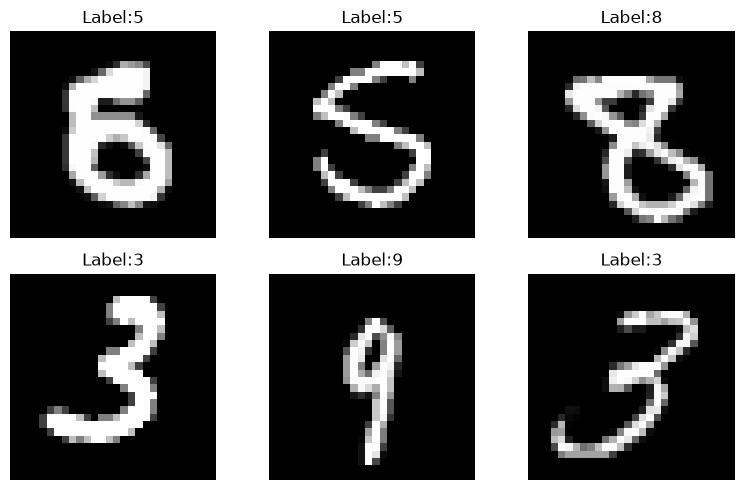

In [3]:
import matplotlib.pyplot as plt

#显示前6张图片
fig, axes=plt.subplots(2,3,figsize=(8,5))
for i,ax in enumerate(axes.flat):
    img=images[i].squeeze() #去掉通道维度(1,28,28) -> (28,28)
    ax.imshow(img,cmap='gray')
    ax.set_title(f'Label:{labels[i].item()}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#从列表创建张量
a=torch.tensor([[1,2],[3,4]])
print("a:\n",a) #打印a的含义？

#全零张量
b=torch.zeros(3,4)
print("b:\n",b)

#全一张量
c=torch.ones(2,3)
print("c:\n",c)

#随机张量
d=torch.randn(2,3)
print("d:\n",d)


a:
 tensor([[1, 2],
        [3, 4]])
b:
 tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
c:
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
d:
 tensor([[-0.0586,  0.7479, -1.1629],
        [-0.4959, -0.2748,  2.0266]])


In [ ]:
x=torch.randn(4,6)
print("原始形状:",x.shape)

# view 改变形状（要求元素总数不变）
y=x.view(3,8)
print("view(3,8) 形状：",y.shape)

#reshape 类似，但更灵活
z=x.reshape(2,12)
print("reshape(2,12) 形状：",z.shape)

# 拼接两个张量
x1=torch.randn(2,3)
x2=torch.randn(2,3)
cat_row=torch.cat((x1,x2),dim=0)  #按行拼接
cat_col=torch.cat((x1,x2),dim=1)  #按列拼接
print("cat_row 形状：",cat_row.shape)
print("cat_col 形状: ",cat_col.shape)


原始形状: torch.Size([4, 6])
xiew(3,8) 形状： torch.Size([3, 8])
reshape(2,12) 形状： torch.Size([2, 12])
cat_row 形状： torch.Size([4, 3])
cat_col 形状:  torch.Size([2, 6])


In [6]:
x=torch.randn(3,4)
print("x:\n",x)

#取第一行
print("第一行：",x[0,:])

#取第二列
print("第二列：",x[:,1])

#取前两行后两列
print("子区域:\n",x[:2,2:])

#布尔索引（选出大于0的元素）
print("大于0的元素:",x[x>0])


x:
 tensor([[-0.8946,  0.1406,  0.3443, -0.3276],
        [ 0.3007, -0.7089,  0.5658, -0.8272],
        [ 0.5861,  0.5150, -0.3682, -0.0984]])
第一行： tensor([-0.8946,  0.1406,  0.3443, -0.3276])
第二列： tensor([ 0.1406, -0.7089,  0.5150])
子区域:
 tensor([[ 0.3443, -0.3276],
        [ 0.5658, -0.8272]])
大于0的元素: tensor([0.1406, 0.3443, 0.3007, 0.5658, 0.5861, 0.5150])


In [8]:
a=torch.tensor([1,2,3])
b=torch.tensor([4,5,6])

#逐元素加法
print("a+b=",a+b)

#矩阵乘法（需调整形状)
a_mat=a.view(1,3)
b_mat=b.view(3,1)
print("矩阵乘法:\n",torch.matmul(a_mat,b_mat))

#求和、均值
print("a的值:",a.sum())
print("b的均值:",b.float().mean().item())

a+b= tensor([5, 7, 9])
矩阵乘法:
 tensor([[32]])
a的值: tensor(6)
b的均值: 5.0


In [9]:
# 测试集
testset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)
testloader = torch.utils.data.DataLoader(testset, batch_size=32, shuffle=False)

print("训练集样本数:", len(trainset))
print("测试集样本数:", len(testset))

训练集样本数: 60000
测试集样本数: 10000


In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = self.dropout1(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout2(x)
        x = self.fc2(x)
        return F.log_softmax(x, dim=1)

In [11]:
# 自动选择 GPU 或 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("使用设备:", device)

model = CNN().to(device)

# 损失函数：配合 log_softmax 使用
criterion = nn.NLLLoss()

# 优化器：Adam，学习率 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

使用设备: cuda


In [12]:
def train_one_epoch(model, trainloader, criterion, optimizer, device):
    model.train()  # 开启训练模式（Dropout 生效）
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()          # 清空梯度
        outputs = model(images)        # 前向传播
        loss = criterion(outputs, labels)  # 计算损失
        loss.backward()                # 反向传播
        optimizer.step()               # 更新参数

        running_loss += loss.item() * images.size(0)
        pred = outputs.argmax(dim=1)
        correct += (pred == labels).sum().item()
        total += labels.size(0)

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc

In [13]:
def evaluate(model, testloader, criterion, device):
    model.eval()  # 评估模式（Dropout 关闭）
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # 不计算梯度，节省内存
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            pred = outputs.argmax(dim=1)
            correct += (pred == labels).sum().item()
            total += labels.size(0)

    avg_loss = running_loss / total
    acc = correct / total
    return avg_loss, acc

In [14]:
epochs = 5
train_losses, train_accs = [], []
test_losses, test_accs = [], []

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(model, trainloader, criterion, optimizer, device)
    test_loss, test_acc = evaluate(model, testloader, criterion, device)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}")

Epoch [1/5] Train Loss: 0.1839, Train Acc: 0.9451 | Test Loss: 0.0477, Test Acc: 0.9842
Epoch [2/5] Train Loss: 0.0848, Train Acc: 0.9748 | Test Loss: 0.0387, Test Acc: 0.9883
Epoch [3/5] Train Loss: 0.0641, Train Acc: 0.9814 | Test Loss: 0.0347, Test Acc: 0.9893
Epoch [4/5] Train Loss: 0.0525, Train Acc: 0.9837 | Test Loss: 0.0310, Test Acc: 0.9904
Epoch [5/5] Train Loss: 0.0442, Train Acc: 0.9861 | Test Loss: 0.0350, Test Acc: 0.9902


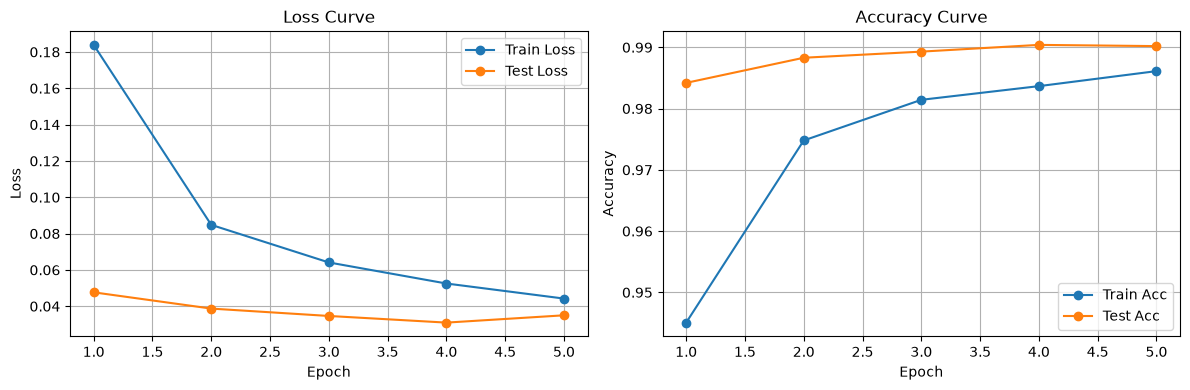

In [22]:
import matplotlib.pyplot as plt

epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', marker='o')
plt.plot(epochs_range, test_losses, label='Test Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accs, label='Train Acc', marker='o')
plt.plot(epochs_range, test_accs, label='Test Acc', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

plt.tight_layout()

# 关键：先保存，再 show
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')

plt.show()

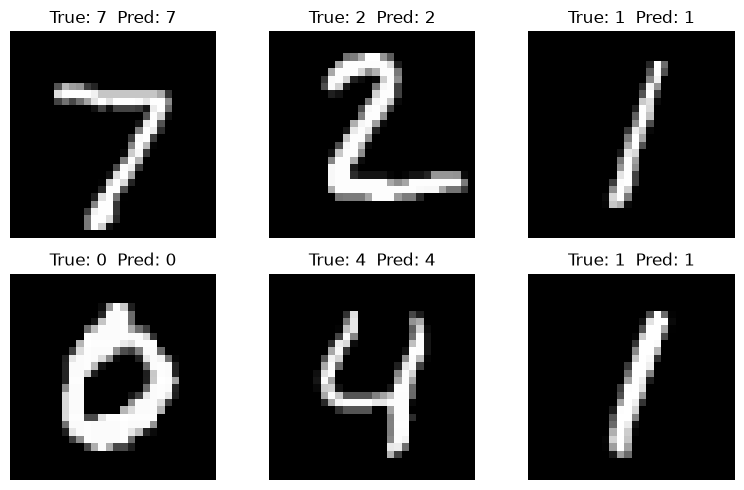

In [16]:
# 取一个 batch 的测试数据
dataiter = iter(testloader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

model.eval()
with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(dim=1)

# 显示前 6 张
fig, axes = plt.subplots(2, 3, figsize=(8, 5))
for i, ax in enumerate(axes.flat):
    img = images[i].cpu().squeeze()
    ax.imshow(img, cmap='gray')
    ax.set_title(f"True: {labels[i].item()}  Pred: {preds[i].item()}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [17]:
class_correct = [0] * 10
class_total = [0] * 10

model.eval()
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        for label, pred in zip(labels, preds):
            if label == pred:
                class_correct[label.item()] += 1
            class_total[label.item()] += 1

for i in range(10):
    acc = class_correct[i] / class_total[i]
    print(f"数字 {i}: {acc:.4f} ({class_correct[i]}/{class_total[i]})")

数字 0: 0.9939 (974/980)
数字 1: 0.9982 (1133/1135)
数字 2: 0.9903 (1022/1032)
数字 3: 0.9960 (1006/1010)
数字 4: 0.9980 (980/982)
数字 5: 0.9955 (888/892)
数字 6: 0.9697 (929/958)
数字 7: 0.9912 (1019/1028)
数字 8: 0.9908 (965/974)
数字 9: 0.9772 (986/1009)


In [18]:
torch.save(model.state_dict(), "mnist_cnn.pth")
print("模型已保存")

模型已保存


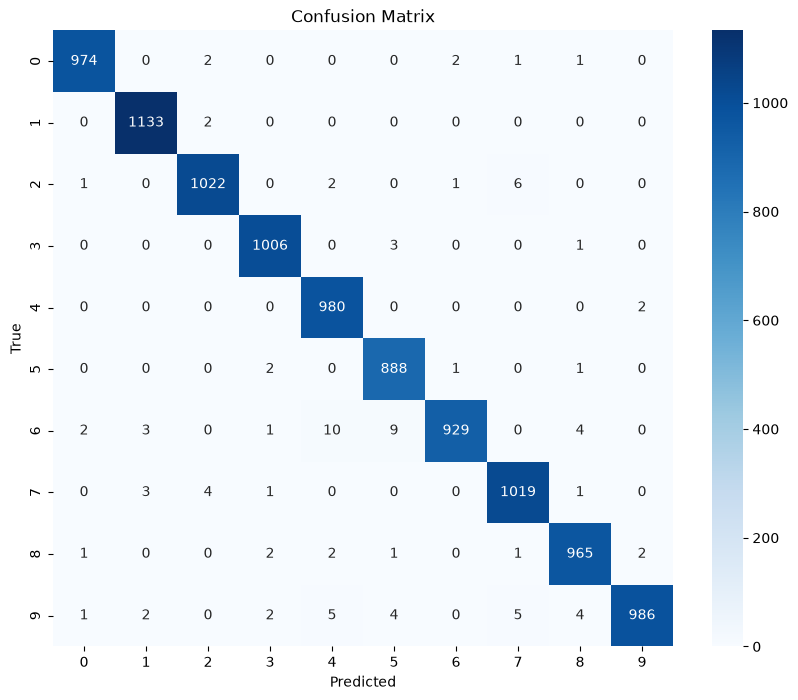

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 收集所有预测
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

总共错分样本数: 98


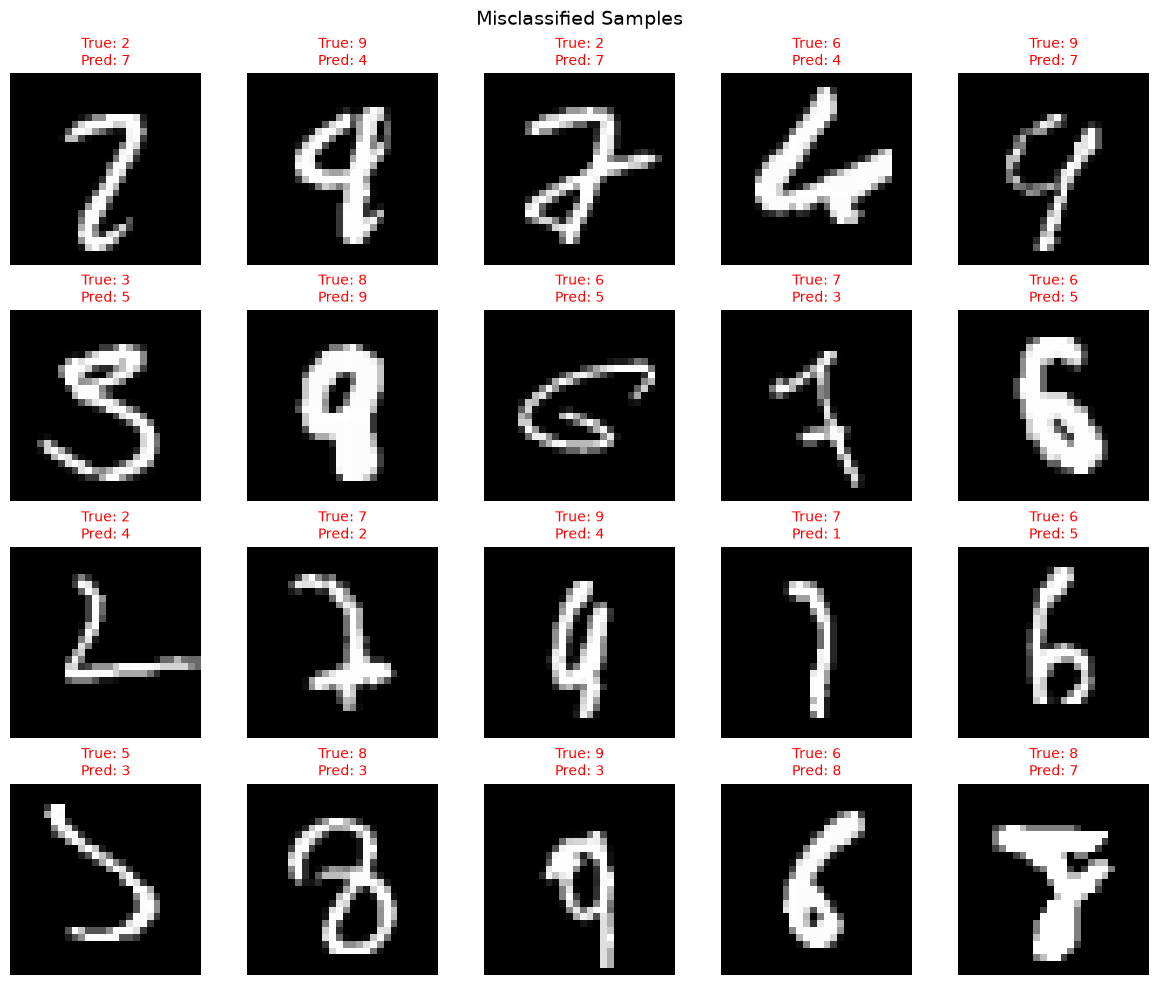

In [24]:
wrong_images, wrong_labels, wrong_preds = [], [], []
model.eval()
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        mask = (preds != labels)
        wrong_images.append(images[mask].cpu())
        wrong_labels.append(labels[mask].cpu())
        wrong_preds.append(preds[mask].cpu())

wrong_images = torch.cat(wrong_images)
wrong_labels = torch.cat(wrong_labels)
wrong_preds = torch.cat(wrong_preds)

print(f"总共错分样本数: {len(wrong_images)}")

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i, ax in enumerate(axes.flat):
    if i >= len(wrong_images):
        ax.axis('off')
        continue
    ax.imshow(wrong_images[i].squeeze(), cmap='gray')
    ax.set_title(f"True: {wrong_labels[i].item()}\nPred: {wrong_preds[i].item()}", 
                 color='red', fontsize=10)
    ax.axis('off')
plt.suptitle("Misclassified Samples", fontsize=14)
plt.tight_layout()
plt.savefig('misclassified.png', dpi=150, bbox_inches='tight')
plt.show()